### EDA do experimento `mass_balance_cascade` (MLflow)

Compara o ensemble de 5 modelos (`mimo_sys.training.ensemble`) com a versão
final, em que a previsão de `nivel_res` é recalculada por uma cascata física
(`mimo_sys.training.mass_balance_cascade`) a partir da própria previsão de
`vazao_distribuicao` do ensemble. Metodologia completa em
`docs/7_tecnica-cascata-fisica.md`; nota de mudança em
`docs/changes/2026-10-16-r2-push-experiment.md`. Treinado por
`notebooks/training/scripts/run_mass_balance_cascade_v2.py`.

In [1]:
from pathlib import Path

import mlflow
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

MLFLOW_DB = Path("../training/mlflow.db")
EXPERIMENT_NAME = "mimo_sys_mass_balance_cascade"

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")

/home/rwp/code/mimo_sys/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Runs do experimento

Um run por membro do ensemble (baseline de cada arquitetura/seed), mais `ensemble_ml` (média simples dos 5) e `ensemble_cascade` (igual, mas `nivel_res` vem da cascata física).

In [2]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])
runs = runs.rename(columns={"tags.mlflow.runName": "run"}).set_index("run")

print(f"{len(runs)} runs em '{EXPERIMENT_NAME}'")
runs[["status", "start_time"]]

7 runs em 'mimo_sys_mass_balance_cascade'


,status,start_time
run,,
ensemble_cascade,FINISHED,2026-10-16 17:54:20.633000+00:00
ensemble_ml,FINISHED,2026-10-16 17:54:16.792000+00:00
seq2seq_s43,FINISHED,2026-10-16 17:53:27.428000+00:00
seq2seq_s42,FINISHED,2026-10-16 17:52:50.242000+00:00
stemgnn_s43,FINISHED,2026-10-16 17:52:28.439000+00:00
mpnn_base_s42,FINISHED,2026-10-16 17:51:56.574000+00:00
mpnn_md8_s42,FINISHED,2026-10-16 17:51:28.074000+00:00


### Métricas por saída (teste, forecast encadeado, escala original)

`ensemble_ml`/`ensemble_cascade` têm a tabela completa (vêm de `metrics_table`); os membros individuais têm só as métricas `chained_*` do próprio `train()`.

In [3]:
OUTPUT_COLS = ["vazao_distribuicao", "nivel_res", "pressao"]
ENSEMBLE_RUNS = ["ensemble_ml", "ensemble_cascade"]


def r2_table(run_names: list[str], prefix: str) -> pd.DataFrame:
    """Uma coluna por saída, R², para os runs de `run_names`."""
    cols = {out: f"metrics.{prefix}r2_{out}" for out in OUTPUT_COLS}
    cols = {k: v for k, v in cols.items() if v in runs.columns}
    return runs.loc[run_names, list(cols.values())].rename(
        columns={v: k for k, v in cols.items()}
    )


r2_members = r2_table(
    [r for r in runs.index if r not in ENSEMBLE_RUNS], prefix="chained_"
)
r2_ensembles = r2_table(ENSEMBLE_RUNS, prefix="")
r2 = pd.concat([r2_members, r2_ensembles])
r2["r2_medio"] = r2.mean(axis=1)
r2.round(3).sort_values("r2_medio", ascending=False)

,vazao_distribuicao,nivel_res,pressao,r2_medio
run,,,,
ensemble_cascade,0.929,0.758,0.740,0.809
ensemble_ml,0.929,0.508,0.740,0.726
mpnn_base_s42,0.920,0.462,0.739,0.707
seq2seq_s43,0.902,0.376,0.734,0.671
seq2seq_s42,0.873,0.453,0.682,0.669
stemgnn_s43,0.894,0.381,0.680,0.652
mpnn_md8_s42,0.918,0.384,0.654,0.652


Ganho de R² médio: do melhor membro individual, para o ensemble de ML, para a cascata física.

In [4]:
best_member = r2_members["r2_medio"] if "r2_medio" in r2_members else r2.loc[r2_members.index, OUTPUT_COLS].mean(axis=1)
resumo = pd.DataFrame({
    "r2_medio": [
        best_member.max(),
        r2.loc["ensemble_ml", OUTPUT_COLS].mean(),
        r2.loc["ensemble_cascade", OUTPUT_COLS].mean(),
    ],
}, index=["melhor membro individual", "ensemble_ml", "ensemble_cascade"])
resumo.round(3)

,r2_medio
melhor membro individual,0.707
ensemble_ml,0.726
ensemble_cascade,0.809


### Energia por banda espectral — `nivel_res`

Erro relativo de energia (%) nas bandas de `docs/5_eda-series-temporais.md` §7, antes e depois da cascata.

In [5]:
def band_pivot(output: str) -> pd.DataFrame:
    """Runs de ensemble × banda, erro relativo de energia (%)."""
    band_order = [
        "tendencia_acima_32h",
        "diario_16-32h",
        "harmonico_8-16h",
        "curto_4-8h",
        "ruido_2-4h",
    ]
    cols = {
        band: f"metrics.energia_rel_pct_{band}_{output}" for band in band_order
    }
    cols = {k: v for k, v in cols.items() if v in runs.columns}
    return runs.loc[ENSEMBLE_RUNS, list(cols.values())].rename(
        columns={v: k for k, v in cols.items()}
    )


band_pivot("nivel_res").round(1)

,tendencia_acima_32h,diario_16-32h,harmonico_8-16h,curto_4-8h,ruido_2-4h
run,,,,,
ensemble_ml,-73.7,-6.3,-54.6,-58.9,-12.5
ensemble_cascade,-3.6,29.6,-37.4,-12.2,62.5


### Figuras — medido vs. previsto e espectro

Comparação lado a lado: `ensemble_ml` (nível ainda fraco) vs. `ensemble_cascade` (nível recalculado pela física).

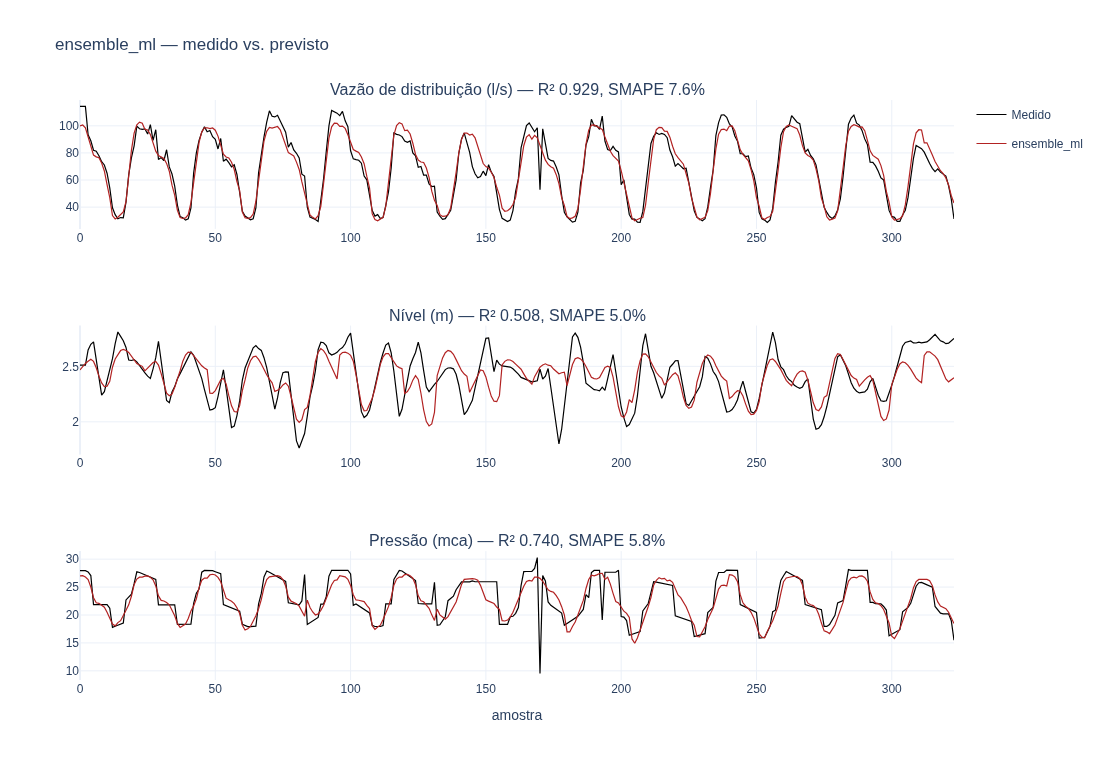

In [6]:
from IPython.display import Image
from mlflow.tracking import MlflowClient

client = MlflowClient()


def show_artifact(run_name: str, nome: str) -> Image:
    """Baixa e mostra um PNG de artefato do run `run_name` ('serie.png' ou 'espectro.png')."""
    run_id = runs.loc[run_name, "run_id"]
    local_path = client.download_artifacts(run_id, nome)
    return Image(local_path)


show_artifact("ensemble_ml", "serie.png")

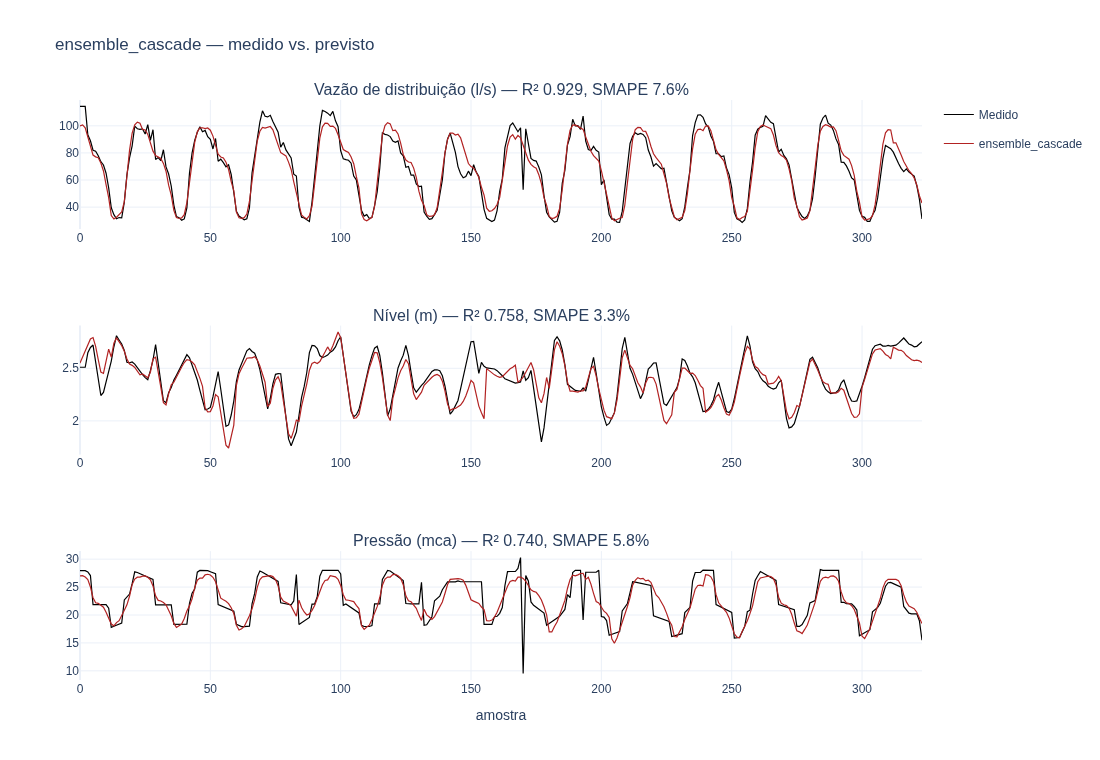

In [7]:
show_artifact("ensemble_cascade", "serie.png")

O espectro mostra o mesmo efeito no domínio da frequência — a cascata recupera energia nas bandas que o ensemble de ML perdia em `nivel_res`.

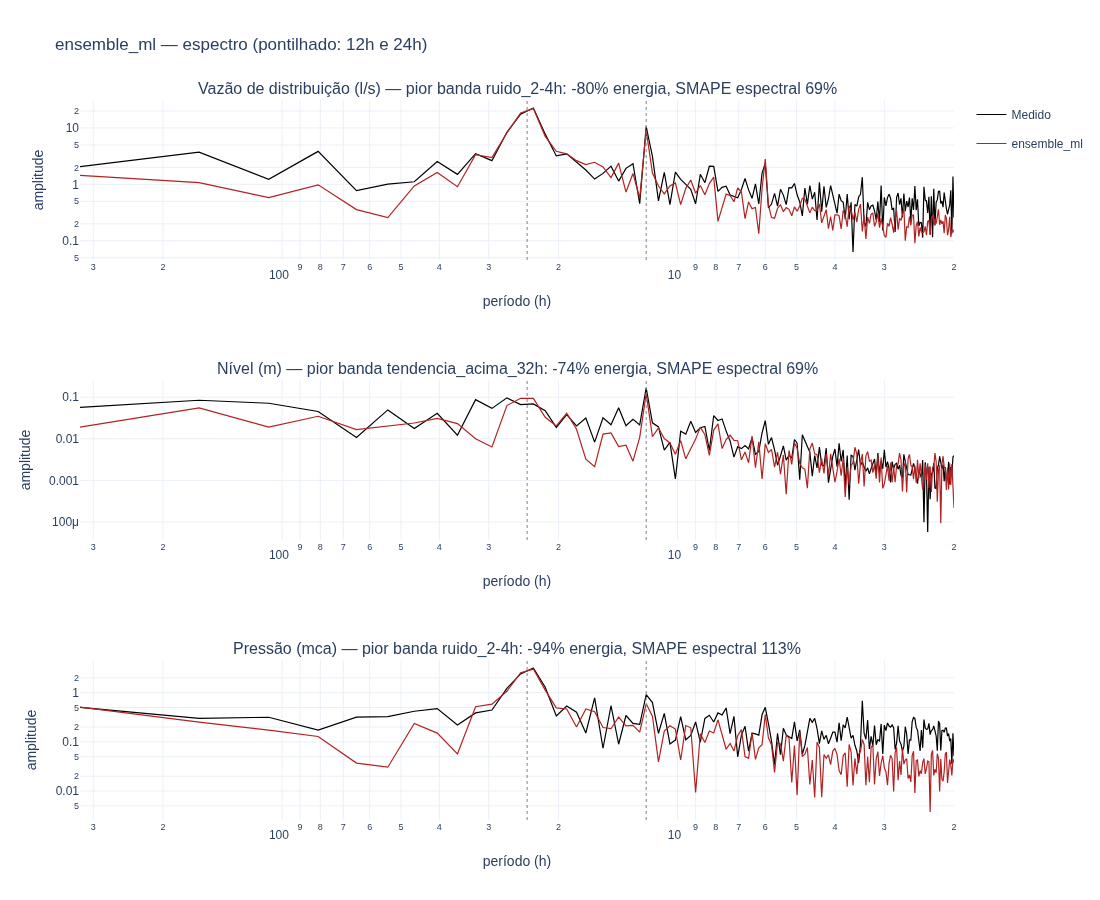

In [8]:
show_artifact("ensemble_ml", "espectro.png")

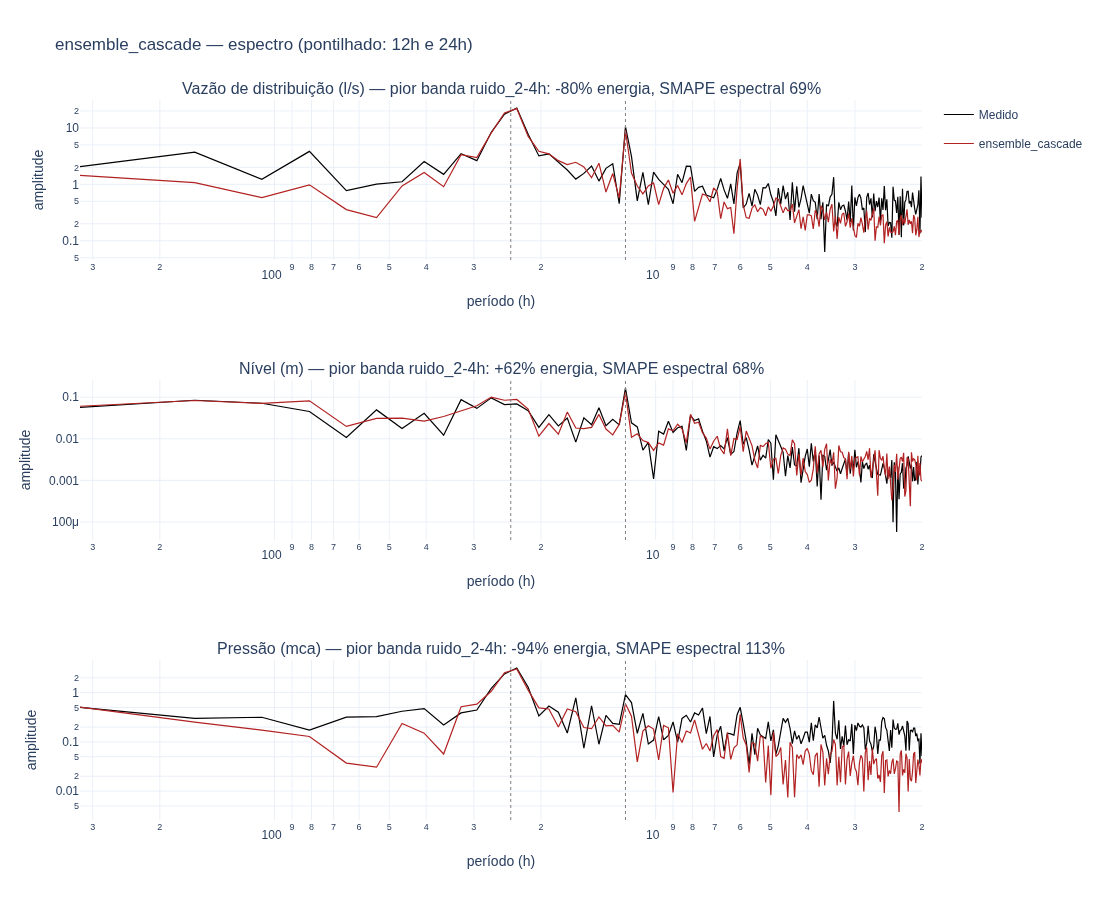

In [9]:
show_artifact("ensemble_cascade", "espectro.png")